# LSTM + Transformer 앙상블 비교 분석
**목표:** 4가지 앙상블 방법을 비교하여 최적 방법 선정  
**비교 방법:**
1. BO 최적 가중치 앙상블 (Weighted Average via Optuna)
2. XGBoost 스태킹
3. Random Forest 스태킹
4. ⭐ Ridge 스태킹 (과적합 방지 메타 학습기)

**평가 지표:** RMSE / MAE / R² (VOL, SPD, OCC 각각)  
**전제 조건:** LSTM·Transformer 노트북 실행 완료 후 아래 파일들이 존재해야 합니다.
```
best_lstm_model.pt        ← LSTM 가중치
best_transformer_model.pt ← Transformer 가중치
scalers.pkl               ← 스케일러
tr_test_preds.npy         ← Transformer 테스트 예측값
tr_test_trues.npy         ← 테스트 정답값
```

## 0. 라이브러리 및 환경 설정

In [1]:
# 필요 패키지 설치 (최초 1회)
# !pip install xgboost scikit-learn optuna torch numpy pandas matplotlib seaborn -q

In [2]:
import os, gc, json, pickle, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from datetime import datetime
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)

import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.multioutput import MultiOutputRegressor

warnings.filterwarnings('ignore')

SEED   = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'디바이스: {DEVICE}')

# 결과 저장 폴더
ENS_DIR = 'ensemble_results'
os.makedirs(ENS_DIR, exist_ok=True)
print(f'결과 저장 폴더: {ENS_DIR}/')

d:\Python\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


디바이스: cuda
결과 저장 폴더: ensemble_results/


## 1. 모델 구조 정의 (LSTM·Transformer 재현용)

In [3]:
# ── LSTM 모델 정의 ───────────────────────────────────────────
class TrafficLSTM(nn.Module):
    def __init__(self, num_numeric_features, num_routes, route_emb_dim,
                 num_links, link_emb_dim, hidden_size=512, num_layers=3,
                 dropout=0.3, output_size=3, pred_steps=3):
        super().__init__()
        self.route_emb = nn.Embedding(num_routes, route_emb_dim)
        self.link_emb  = nn.Embedding(num_links,  link_emb_dim)
        lstm_input_dim = num_numeric_features + route_emb_dim + link_emb_dim
        self.lstm = nn.LSTM(input_size=lstm_input_dim, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, output_size * pred_steps)
        )

    def forward(self, x_num, x_cat):
        route_e = self.route_emb(x_cat[:, 0])
        link_e  = self.link_emb(x_cat[:, 1])
        cat_e   = torch.cat([route_e, link_e], dim=-1)
        cat_e   = cat_e.unsqueeze(1).expand(-1, x_num.size(1), -1)
        x       = torch.cat([x_num, cat_e], dim=-1)
        out, _  = self.lstm(x)
        return self.fc(self.dropout(out[:, -1, :]))


# ── Transformer 모델 정의 ────────────────────────────────────
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe  = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])


class TrafficTransformer(nn.Module):
    def __init__(self, num_numeric_features, num_routes, route_emb_dim,
                 num_links, link_emb_dim, d_model=128, nhead=4,
                 num_layers=2, dim_ff=256, dropout=0.1,
                 output_size=3, pred_steps=3):
        super().__init__()
        self.route_emb  = nn.Embedding(num_routes, route_emb_dim)
        self.link_emb   = nn.Embedding(num_links,  link_emb_dim)
        input_dim       = num_numeric_features + route_emb_dim + link_emb_dim
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_enc    = PositionalEncoding(d_model, dropout=dropout)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
            dropout=dropout, batch_first=True, norm_first=True)
        self.transformer_enc = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.head = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model // 2), nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, output_size * pred_steps)
        )

    def forward(self, x_num, x_cat):
        route_e = self.route_emb(x_cat[:, 0])
        link_e  = self.link_emb(x_cat[:, 1])
        cat_e   = torch.cat([route_e, link_e], dim=-1)
        cat_e   = cat_e.unsqueeze(1).expand(-1, x_num.size(1), -1)
        x       = self.input_proj(torch.cat([x_num, cat_e], dim=-1))
        x       = self.transformer_enc(self.pos_enc(x))
        return self.head(x[:, -1, :])

print('모델 클래스 정의 완료')

모델 클래스 정의 완료


## 2. 저장된 데이터 및 모델 로드

In [4]:
# ⚙️ 경로 설정 — LSTM·Transformer 노트북과 같은 폴더에서 실행 시 그대로 사용
LSTM_MODEL_PATH = 'best_lstm_model.pt'
TR_MODEL_PATH   = 'best_transformer_model.pt'
SCALERS_PATH    = 'scalers.pkl'
LSTM_CONFIG_PATH= 'model_config.pkl'
TR_CONFIG_PATH  = 'tr_model_config.pkl'

# 스케일러 로드
with open(SCALERS_PATH, 'rb') as f:
    scalers = pickle.load(f)

# 모델 설정 로드
with open(LSTM_CONFIG_PATH, 'rb') as f:
    lstm_cfg = pickle.load(f)
with open(TR_CONFIG_PATH, 'rb') as f:
    tr_cfg = pickle.load(f)

print('LSTM config:', {k: v for k, v in lstm_cfg.items() if k != 'num_features'})
print('TR   config:', {k: v for k, v in tr_cfg.items()   if k != 'num_features'})

LSTM config: {'num_numeric_features': 22, 'num_routes': 16, 'route_emb_dim': 8, 'num_links': 160, 'link_emb_dim': 50, 'hidden_size': 512, 'num_layers': 3, 'dropout': 0.3, 'output_size': 3, 'pred_steps': 3, 'seq_len': 12}
TR   config: {'model': 'Transformer', 'num_numeric_features': 22, 'num_routes': 16, 'route_emb_dim': 8, 'num_links': 160, 'link_emb_dim': 50, 'd_model': 256, 'nhead': 4, 'num_layers': 1, 'dim_ff': 128, 'dropout': 0.05, 'output_size': 3, 'pred_steps': 3, 'seq_len': 12}


In [5]:
# ── 시퀀스 데이터 재로드 (앙상블 val/test 예측용) ────────────
# LSTM/Transformer 노트북에서 X_num, X_cat, y_arr 변수가 이미 메모리에 있으면
# 이 셀을 건너뛰어도 됩니다.
# 없는 경우 아래처럼 저장된 npy 파일을 로드하세요.

# Transformer 노트북 섹션 11에서 저장한 파일 로드
tr_preds_test = np.load('tr_test_preds.npy')   # (N_test, 9)
tr_trues_test = np.load('tr_test_trues.npy')   # (N_test, 9)

print(f'Transformer 테스트 예측값 shape: {tr_preds_test.shape}')
print(f'테스트 정답값 shape: {tr_trues_test.shape}')

Transformer 테스트 예측값 shape: (2473433, 9)
테스트 정답값 shape: (2473433, 9)


In [6]:
# ── LSTM 모델 로드 ────────────────────────────────────────────
lstm_model = TrafficLSTM(
    num_numeric_features = lstm_cfg['num_numeric_features'],
    num_routes           = lstm_cfg['num_routes'],
    route_emb_dim        = lstm_cfg['route_emb_dim'],
    num_links            = lstm_cfg['num_links'],
    link_emb_dim         = lstm_cfg['link_emb_dim'],
    hidden_size          = lstm_cfg['hidden_size'],
    num_layers           = lstm_cfg['num_layers'],
    dropout              = lstm_cfg['dropout'],
    output_size          = lstm_cfg['output_size'],
    pred_steps           = lstm_cfg['pred_steps']
).to(DEVICE)
lstm_model.load_state_dict(torch.load(LSTM_MODEL_PATH, map_location=DEVICE))
lstm_model.eval()
print('LSTM 모델 로드 완료')

# ── Transformer 모델 로드 ─────────────────────────────────────
tr_model = TrafficTransformer(
    num_numeric_features = tr_cfg['num_numeric_features'],
    num_routes           = tr_cfg['num_routes'],
    route_emb_dim        = tr_cfg['route_emb_dim'],
    num_links            = tr_cfg['num_links'],
    link_emb_dim         = tr_cfg['link_emb_dim'],
    d_model              = tr_cfg['d_model'],
    nhead                = tr_cfg['nhead'],
    num_layers           = tr_cfg['num_layers'],
    dim_ff               = tr_cfg['dim_ff'],
    dropout              = tr_cfg['dropout'],
    output_size          = tr_cfg['output_size'],
    pred_steps           = tr_cfg['pred_steps']
).to(DEVICE)
tr_model.load_state_dict(torch.load(TR_MODEL_PATH, map_location=DEVICE))
tr_model.eval()
print('Transformer 모델 로드 완료')

LSTM 모델 로드 완료
Transformer 모델 로드 완료


## 3. Val / Test 예측값 생성

In [7]:
# npy 파일에서 데이터 로드
SAVE_DIR = './'   # npy 파일이 있는 폴더 경로 (같은 폴더면 './')

X_num_val = np.load(os.path.join(SAVE_DIR, 'X_num_val.npy'))
X_cat_val = np.load(os.path.join(SAVE_DIR, 'X_cat_val.npy'))
y_val     = np.load(os.path.join(SAVE_DIR, 'y_val.npy'))
X_num_te  = np.load(os.path.join(SAVE_DIR, 'X_num_te.npy'))
X_cat_te  = np.load(os.path.join(SAVE_DIR, 'X_cat_te.npy'))
y_te      = np.load(os.path.join(SAVE_DIR, 'y_te.npy'))

print(f'X_num_val: {X_num_val.shape}')
print(f'X_num_te:  {X_num_te.shape}')
print('데이터 로드 완료')

X_num_val: (2473433, 12, 22)
X_num_te:  (2473433, 12, 22)
데이터 로드 완료


In [8]:
# TrafficDataset 정의 (LSTM/Transformer 노트북과 동일)
class TrafficDataset(torch.utils.data.Dataset):
    def __init__(self, x_num, x_cat, y):
        self.x_num = x_num
        self.x_cat = x_cat
        self.y     = y
    def __len__(self): return len(self.y)
    def __getitem__(self, idx):
        return (torch.tensor(self.x_num[idx], dtype=torch.float32),
                torch.tensor(self.x_cat[idx], dtype=torch.long),
                torch.tensor(self.y[idx],     dtype=torch.float32))

# ── X_num_val, X_cat_val 등이 메모리에 있다고 가정 ────────────
# 없는 경우: LSTM/Transformer 노트북의 섹션 3(시퀀스 생성)까지 실행 후
# 이 노트북으로 돌아오세요.
BATCH_SIZE = 4096

val_ds   = TrafficDataset(X_num_val, X_cat_val, y_val)
test_ds  = TrafficDataset(X_num_te,  X_cat_te,  y_te)

val_loader  = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=True)
print('DataLoader 준비 완료')

DataLoader 준비 완료


In [9]:
@torch.no_grad()
def get_predictions(model, loader):
    """모델 추론 → numpy 반환"""
    preds, trues = [], []
    model.eval()
    for xn, xc, y in tqdm(loader, desc=f'추론', leave=False):
        xn, xc = xn.to(DEVICE), xc.to(DEVICE)
        with torch.cuda.amp.autocast():
            pred = model(xn, xc).cpu().numpy()
        preds.append(pred)
        trues.append(y.numpy())
    return np.concatenate(preds), np.concatenate(trues)

print('Val 예측 생성 중...')
lstm_preds_val,  y_val_true  = get_predictions(lstm_model, val_loader)
tr_preds_val,    _           = get_predictions(tr_model,   val_loader)

print('Test 예측 생성 중...')
lstm_preds_test, y_test_true = get_predictions(lstm_model, test_loader)
tr_preds_test2,  _           = get_predictions(tr_model,   test_loader)

# tr_test_preds.npy 로드값과 비교 확인 (일치해야 함)
print(f'LSTM  Val pred  shape: {lstm_preds_val.shape}')
print(f'TR    Val pred  shape: {tr_preds_val.shape}')
print(f'LSTM  Test pred shape: {lstm_preds_test.shape}')
print(f'정답  Test      shape: {y_test_true.shape}')

Val 예측 생성 중...


Test 예측 생성 중...


LSTM  Val pred  shape: (2473433, 9)
TR    Val pred  shape: (2473433, 9)
LSTM  Test pred shape: (2473433, 9)
정답  Test      shape: (2473433, 9)


## 4. 앙상블 방법 정의

**스태킹 구조:**
```
LSTM 예측 (9차원)  ─┐
                    ├─► [18차원 피처] ─► 메타 학습기 ─► 최종 예측 (9차원)
TR   예측 (9차원)  ─┘
```
- Val 예측값으로 메타 학습기 학습
- Test 예측값으로 최종 평가

In [10]:
# 스태킹 피처 구성: LSTM 예측 + TR 예측 concat
# Val용 (메타 학습기 학습)
X_meta_val  = np.concatenate([lstm_preds_val,  tr_preds_val],   axis=1)  # (N_val, 18)
y_meta_val  = y_val_true                                                  # (N_val, 9)

# Test용 (최종 평가)
X_meta_test = np.concatenate([lstm_preds_test, tr_preds_test2], axis=1)  # (N_test, 18)
y_meta_test = y_test_true                                                 # (N_test, 9)

# OUTPUT_DIM: 9 = PRED_STEPS(3) × TARGET(3)
OUTPUT_DIM  = y_meta_val.shape[1]
TARGET_NAMES = ['VOL', 'SPD', 'OCC']
PRED_STEPS   = lstm_cfg['pred_steps']

print(f'Meta 피처 shape (Val):  {X_meta_val.shape}')
print(f'Meta 피처 shape (Test): {X_meta_test.shape}')
print(f'출력 차원: {OUTPUT_DIM} ({PRED_STEPS} steps × 3 targets)')

Meta 피처 shape (Val):  (2473433, 18)
Meta 피처 shape (Test): (2473433, 18)
출력 차원: 9 (3 steps × 3 targets)


In [11]:
# 역변환 함수
def inverse_vol(x): return np.expm1(scalers['VOL'].inverse_transform(x.reshape(-1,1)).flatten())
def inverse_spd(x): return scalers['SPD'].inverse_transform(x.reshape(-1,1)).flatten()
def inverse_occ(x): return np.expm1(scalers['OCC'].inverse_transform(x.reshape(-1,1)).flatten())
inv_funcs = [inverse_vol, inverse_spd, inverse_occ]

def compute_metrics(preds, trues):
    """
    preds, trues: (N, PRED_STEPS*3)
    returns: dict {target_name: {step: {rmse, mae, r2}}}
    """
    results = {}
    for t_idx, (tname, inv_fn) in enumerate(zip(TARGET_NAMES, inv_funcs)):
        results[tname] = {}
        for step in range(PRED_STEPS):
            col = step * 3 + t_idx
            p = inv_fn(preds[:, col])
            y = inv_fn(trues[:, col])
            results[tname][f't+{step+1}'] = {
                'rmse': float(np.sqrt(mean_squared_error(y, p))),
                'mae' : float(mean_absolute_error(y, p)),
                'r2'  : float(r2_score(y, p))
            }
    return results

def flat_metrics(preds, trues):
    """타겟별 평균 메트릭 반환 (보고서용 요약)"""
    m = compute_metrics(preds, trues)
    flat = {}
    for tname in TARGET_NAMES:
        rmses = [m[tname][s]['rmse'] for s in m[tname]]
        maes  = [m[tname][s]['mae']  for s in m[tname]]
        r2s   = [m[tname][s]['r2']   for s in m[tname]]
        flat[tname] = {'rmse': np.mean(rmses), 'mae': np.mean(maes), 'r2': np.mean(r2s)}
    return flat

# 단일 모델 기준 성능 계산 (비교 베이스라인)
lstm_metrics = flat_metrics(lstm_preds_test, y_test_true)
tr_metrics   = flat_metrics(tr_preds_test2,  y_test_true)

print('베이스라인 성능 (LSTM):')
for t, m in lstm_metrics.items():
    print(f'  {t}: RMSE={m["rmse"]:.4f}  MAE={m["mae"]:.4f}  R²={m["r2"]:.4f}')
print('베이스라인 성능 (Transformer):')
for t, m in tr_metrics.items():
    print(f'  {t}: RMSE={m["rmse"]:.4f}  MAE={m["mae"]:.4f}  R²={m["r2"]:.4f}')

베이스라인 성능 (LSTM):
  VOL: RMSE=25.0705  MAE=17.9696  R²=0.9364
  SPD: RMSE=5.9865  MAE=3.8683  R²=0.8775
  OCC: RMSE=3.6410  MAE=2.1453  R²=0.8779
베이스라인 성능 (Transformer):
  VOL: RMSE=23.3661  MAE=16.2490  R²=0.9447
  SPD: RMSE=5.5293  MAE=3.4878  R²=0.8939
  OCC: RMSE=3.2541  MAE=1.8063  R²=0.9002


## 5. 방법 1 — BO 최적 가중치 앙상블

In [12]:
# ══════════════════════════════════════════════════════════════
# 방법 1 — BO 최적 가중치 앙상블
# · VOL (교통량)만 BO로 앙상블 → 다익스트라에서 VOL 비용에 사용
# · SPD / OCC 는 Ridge 앙상블 결과를 사용 (셀 23 참조)
# ══════════════════════════════════════════════════════════════

# ── 출력 차원 인덱스 매핑 ─────────────────────────────────────
# 출력 순서: [VOL_t+1, SPD_t+1, OCC_t+1, VOL_t+2, SPD_t+2, OCC_t+2, ...]
# 즉 col = step*3 + target_idx  (VOL=0, SPD=1, OCC=2)
VOL_COLS = [step * 3 + 0 for step in range(PRED_STEPS)]  # [0, 3, 6]
SPD_COLS = [step * 3 + 1 for step in range(PRED_STEPS)]  # [1, 4, 7]
OCC_COLS = [step * 3 + 2 for step in range(PRED_STEPS)]  # [2, 5, 8]

print(f'VOL 차원 인덱스: {VOL_COLS}')
print(f'SPD 차원 인덱스: {SPD_COLS}')
print(f'OCC 차원 인덱스: {OCC_COLS}')

# ── BO 탐색: VOL 3개 차원만 가중치 최적화 ─────────────────────
def bo_vol_objective(trial):
    """VOL(t+1, t+2, t+3) 3개 차원에 대해 독립 가중치 탐색"""
    w = np.array([trial.suggest_float(f'w_vol_{s}', 0.0, 1.0)
                  for s in range(PRED_STEPS)])  # shape (3,)

    mse_total = 0.0
    for k, col in enumerate(VOL_COLS):
        pred_blend = (w[k] * lstm_preds_val[:, col]
                      + (1 - w[k]) * tr_preds_val[:, col])
        mse_total += float(np.mean((pred_blend - y_meta_val[:, col]) ** 2))
    return mse_total / PRED_STEPS


print('BO 가중치 탐색 시작 (VOL 전용, 200 trials)...')
bo_weight_study = optuna.create_study(
    direction='minimize',
    sampler=TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10)
)
bo_weight_study.optimize(bo_vol_objective, n_trials=200, show_progress_bar=True)

# ── 최적 가중치 추출 (3차원: VOL t+1/t+2/t+3) ─────────────────
best_vol_weights = np.array(
    [bo_weight_study.best_params[f'w_vol_{s}'] for s in range(PRED_STEPS)]
)  # shape: (3,)

# 다익스트라 저장용: 9차원으로 확장
# VOL 위치(col 0,3,6)에 BO 가중치, SPD/OCC 위치는 0.5 기본값 (Ridge로 대체되므로 미사용)
best_weights_9d = np.full(OUTPUT_DIM, 0.5)  # (9,)
for k, col in enumerate(VOL_COLS):
    best_weights_9d[col] = best_vol_weights[k]

print(f'\n최적 Val MSE (VOL): {bo_weight_study.best_value:.6f}')
for k, col in enumerate(VOL_COLS):
    print(f'  VOL t+{k+1}: LSTM={best_vol_weights[k]:.3f} / TR={1-best_vol_weights[k]:.3f}')

# ── VOL BO 앙상블 테스트 예측 생성 ───────────────────────────────
bo_preds_test = lstm_preds_test.copy()
for k, col in enumerate(VOL_COLS):
    w = best_vol_weights[k]
    bo_preds_test[:, col] = (
        w * lstm_preds_test[:, col]
        + (1 - w) * tr_preds_test2[:, col]
    )

bo_metrics = flat_metrics(bo_preds_test, y_test_true)
print('\nBO 가중치 앙상블 (VOL 한정) 테스트 성능:')
for t, m in bo_metrics.items():
    print(f'  {t}: RMSE={m["rmse"]:.4f}  MAE={m["mae"]:.4f}  R²={m["r2"]:.4f}')


VOL 차원 인덱스: [0, 3, 6]
SPD 차원 인덱스: [1, 4, 7]
OCC 차원 인덱스: [2, 5, 8]
BO 가중치 탐색 시작 (VOL 전용, 200 trials)...


Best trial: 121. Best value: 0.0481103: 100%|██████████| 200/200 [00:25<00:00,  7.98it/s]



최적 Val MSE (VOL): 0.048110
  VOL t+1: LSTM=0.125 / TR=0.875
  VOL t+2: LSTM=0.088 / TR=0.912
  VOL t+3: LSTM=0.140 / TR=0.860

BO 가중치 앙상블 (VOL 한정) 테스트 성능:
  VOL: RMSE=23.2201  MAE=16.1459  R²=0.9453
  SPD: RMSE=5.9865  MAE=3.8683  R²=0.8775
  OCC: RMSE=3.6410  MAE=2.1453  R²=0.8779


## 6. 방법 2 — XGBoost 스태킹

In [13]:
# XGBoost: 출력이 9차원이므로 MultiOutputRegressor 사용
print('XGBoost 학습 중...')

xgb_base = xgb.XGBRegressor(
    n_estimators     = 300,
    max_depth        = 4,
    learning_rate    = 0.05,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    random_state     = SEED,
    tree_method      = 'hist',      # GPU 사용: 'gpu_hist'
    device           = 'cuda',      # RTX 5070 활용
    verbosity        = 0
)
xgb_model = MultiOutputRegressor(xgb_base, n_jobs=1)
xgb_model.fit(X_meta_val, y_meta_val)

xgb_preds_test = xgb_model.predict(X_meta_test)
xgb_metrics    = flat_metrics(xgb_preds_test, y_test_true)

print('XGBoost 앙상블 테스트 성능:')
for t, m in xgb_metrics.items():
    print(f'  {t}: RMSE={m["rmse"]:.4f}  MAE={m["mae"]:.4f}  R²={m["r2"]:.4f}')

XGBoost 학습 중...
XGBoost 앙상블 테스트 성능:
  VOL: RMSE=23.3148  MAE=16.1957  R²=0.9449
  SPD: RMSE=5.4493  MAE=3.3185  R²=0.8967
  OCC: RMSE=3.3845  MAE=1.8216  R²=0.8925


## 7. 방법 3 — Random Forest 스태킹

In [14]:
print('Random Forest 학습 중...')

rf_model = MultiOutputRegressor(
    RandomForestRegressor(
        n_estimators = 200,
        max_depth    = 8,
        min_samples_leaf = 5,
        random_state = SEED,
        n_jobs       = -1     # CPU 전체 코어 사용
    ),
    n_jobs=1
)
rf_model.fit(X_meta_val, y_meta_val)

rf_preds_test = rf_model.predict(X_meta_test)
rf_metrics    = flat_metrics(rf_preds_test, y_test_true)

print('Random Forest 앙상블 테스트 성능:')
for t, m in rf_metrics.items():
    print(f'  {t}: RMSE={m["rmse"]:.4f}  MAE={m["mae"]:.4f}  R²={m["r2"]:.4f}')

Random Forest 학습 중...
Random Forest 앙상블 테스트 성능:
  VOL: RMSE=23.4801  MAE=16.3112  R²=0.9441
  SPD: RMSE=5.4816  MAE=3.3356  R²=0.8954
  OCC: RMSE=3.1699  MAE=1.7325  R²=0.9051


## 8. 방법 4 — Ridge 스태킹 (추천)

In [15]:
# ══════════════════════════════════════════════════════════════
# 방법 4 — Ridge 스태킹
# · SPD / OCC 앙상블에 사용 → 다익스트라 경로 비용에 활용
# · VOL은 BO 앙상블을 사용하므로 Ridge는 SPD/OCC 위주로 평가
# ══════════════════════════════════════════════════════════════
print('Ridge 스태킹 학습 중...')

# alpha(정규화 강도)를 Optuna로 최적화
def ridge_alpha_objective(trial):
    alpha = trial.suggest_float('alpha', 1e-3, 100.0, log=True)
    ridge = MultiOutputRegressor(Ridge(alpha=alpha))
    ridge.fit(X_meta_val, y_meta_val)
    preds = ridge.predict(X_meta_val)
    # SPD/OCC 차원만으로 alpha 최적화
    spd_occ_cols = SPD_COLS + OCC_COLS
    return float(np.mean((preds[:, spd_occ_cols] - y_meta_val[:, spd_occ_cols]) ** 2))

ridge_study = optuna.create_study(direction='minimize', sampler=TPESampler(seed=SEED))
ridge_study.optimize(ridge_alpha_objective, n_trials=50, show_progress_bar=False)
best_alpha = ridge_study.best_params['alpha']
print(f'최적 Ridge alpha: {best_alpha:.4f}')

ridge_model = MultiOutputRegressor(Ridge(alpha=best_alpha))
ridge_model.fit(X_meta_val, y_meta_val)

ridge_preds_test = ridge_model.predict(X_meta_test)
ridge_metrics    = flat_metrics(ridge_preds_test, y_test_true)

# ── Ridge 계수 출력 (LSTM vs TR 기여도, SPD/OCC 위주) ───────────
print('\nRidge 계수 — LSTM / TR 기여도 (SPD·OCC 차원 위주):')
col_labels = [f'VOL_t+{s+1}' if c in VOL_COLS else
               f'SPD_t+{SPD_COLS.index(c)+1}' if c in SPD_COLS else
               f'OCC_t+{OCC_COLS.index(c)+1}'
               for s, c in enumerate(range(OUTPUT_DIM))]
for i, est in enumerate(ridge_model.estimators_):
    tag = col_labels[i]
    lstm_sum = est.coef_[:OUTPUT_DIM].sum()
    tr_sum   = est.coef_[OUTPUT_DIM:].sum()
    marker = ' ← SPD/OCC' if i in (SPD_COLS + OCC_COLS) else ''
    print(f'  {tag:12s}: LSTM={lstm_sum:+.3f}  TR={tr_sum:+.3f}{marker}')

print('\nRidge 앙상블 테스트 성능:')
for t, m in ridge_metrics.items():
    print(f'  {t}: RMSE={m["rmse"]:.4f}  MAE={m["mae"]:.4f}  R²={m["r2"]:.4f}')


Ridge 스태킹 학습 중...
최적 Ridge alpha: 0.0010

Ridge 계수 — LSTM / TR 기여도 (SPD·OCC 차원 위주):
  VOL_t+1     : LSTM=+0.103  TR=+0.904
  SPD_t+1     : LSTM=+0.272  TR=+0.782 ← SPD/OCC
  OCC_t+1     : LSTM=-0.046  TR=+1.087 ← SPD/OCC
  VOL_t+4     : LSTM=-0.014  TR=+1.028
  SPD_t+2     : LSTM=+0.398  TR=+0.636 ← SPD/OCC
  OCC_t+2     : LSTM=-0.097  TR=+1.138 ← SPD/OCC
  VOL_t+7     : LSTM=-0.020  TR=+1.051
  SPD_t+3     : LSTM=+0.483  TR=+0.529 ← SPD/OCC
  OCC_t+3     : LSTM=-0.140  TR=+1.182 ← SPD/OCC

Ridge 앙상블 테스트 성능:
  VOL: RMSE=23.4903  MAE=16.4299  R²=0.9440
  SPD: RMSE=5.4353  MAE=3.3111  R²=0.8972
  OCC: RMSE=3.1199  MAE=1.7472  R²=0.9082


## 9. 결과 종합 비교

In [16]:
# 전체 결과 DataFrame 생성
all_results = {
    'LSTM (단독)'        : lstm_metrics,
    'Transformer (단독)' : tr_metrics,
    'BO 가중치'          : bo_metrics,
    'XGBoost 스태킹'     : xgb_metrics,
    'Random Forest'      : rf_metrics,
    'Ridge 스태킹'       : ridge_metrics,
}

rows = []
for method, metrics in all_results.items():
    for tname, m in metrics.items():
        rows.append({
            '방법'  : method,
            '타겟'  : tname,
            'RMSE'  : round(m['rmse'], 4),
            'MAE'   : round(m['mae'],  4),
            'R²'    : round(m['r2'],   4)
        })

df_results = pd.DataFrame(rows)

# 피벗 테이블 출력
for metric in ['RMSE', 'MAE', 'R²']:
    pivot = df_results.pivot(index='방법', columns='타겟', values=metric)
    # 정렬: RMSE/MAE는 낮을수록, R²는 높을수록 좋음
    ascending = (metric != 'R²')
    pivot['평균'] = pivot.mean(axis=1)
    pivot = pivot.sort_values('평균', ascending=ascending)
    print(f'\n── {metric} (' + ('낮을수록 좋음' if ascending else '높을수록 좋음') + ') ──')
    print(pivot.to_string())

# CSV 저장
_ts = datetime.now().strftime('%Y%m%d_%H%M%S')
df_results.to_csv(os.path.join(ENS_DIR, f'ensemble_comparison_{_ts}.csv'),
                  index=False, encoding='utf-8-sig')
print(f'\n결과 CSV 저장 완료')


── RMSE (낮을수록 좋음) ──
타겟                   OCC     SPD      VOL         평균
방법                                                  
Ridge 스태킹         3.1199  5.4353  23.4903  10.681833
Random Forest     3.1699  5.4816  23.4801  10.710533
XGBoost 스태킹       3.3845  5.4493  23.3148  10.716200
Transformer (단독)  3.2541  5.5293  23.3661  10.716500
BO 가중치            3.6410  5.9865  23.2201  10.949200
LSTM (단독)         3.6410  5.9865  25.0705  11.566000

── MAE (낮을수록 좋음) ──
타겟                   OCC     SPD      VOL        평균
방법                                                 
XGBoost 스태킹       1.8216  3.3185  16.1957  7.111933
Random Forest     1.7325  3.3356  16.3112  7.126433
Ridge 스태킹         1.7472  3.3111  16.4299  7.162733
Transformer (단독)  1.8063  3.4878  16.2490  7.181033
BO 가중치            2.1453  3.8683  16.1459  7.386500
LSTM (단독)         2.1453  3.8683  17.9696  7.994400

── R² (높을수록 좋음) ──
타겟                   OCC     SPD     VOL        평균
방법                                            

## 10. 시각화 — 보고서용 그래프

<Figure size 1000x500 with 0 Axes>

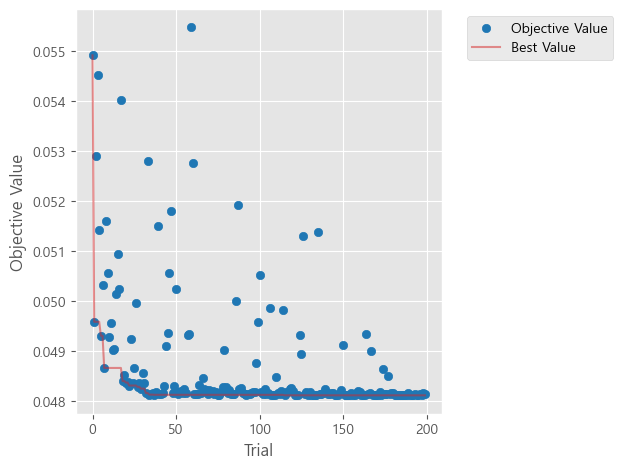

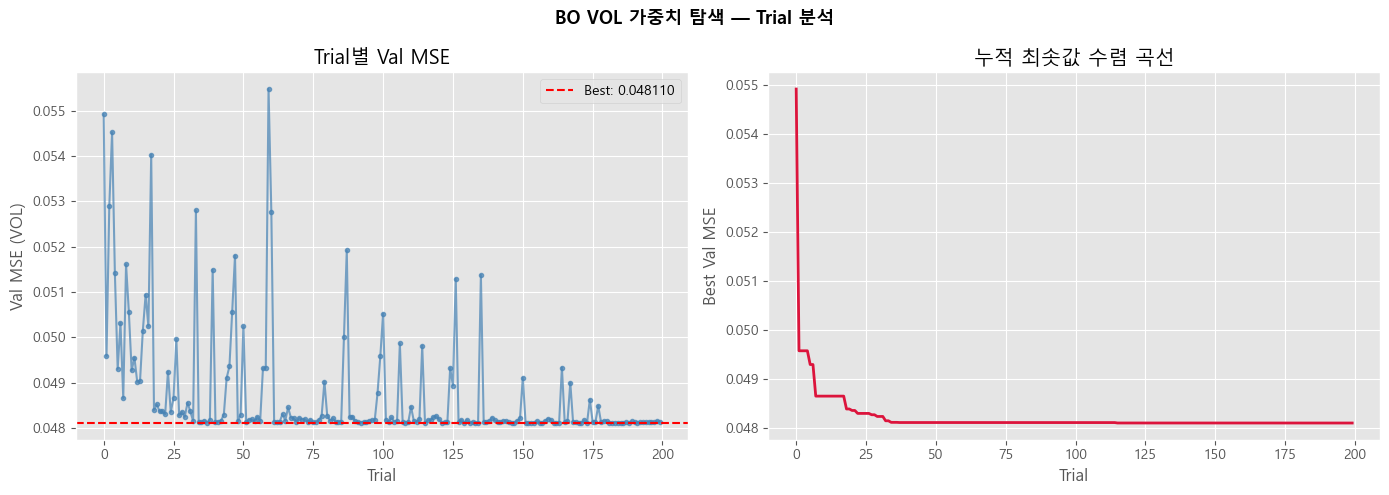

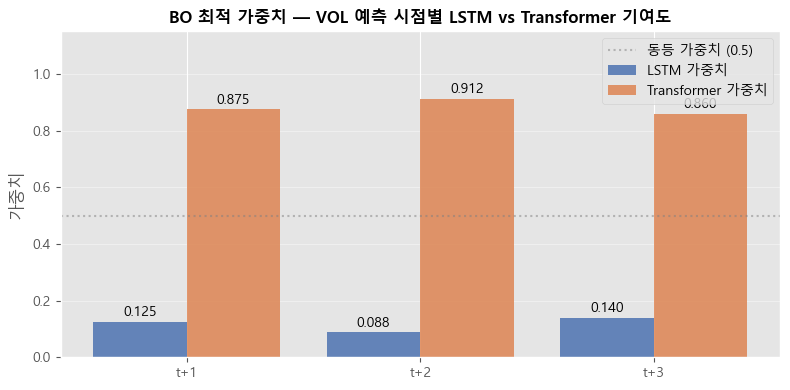

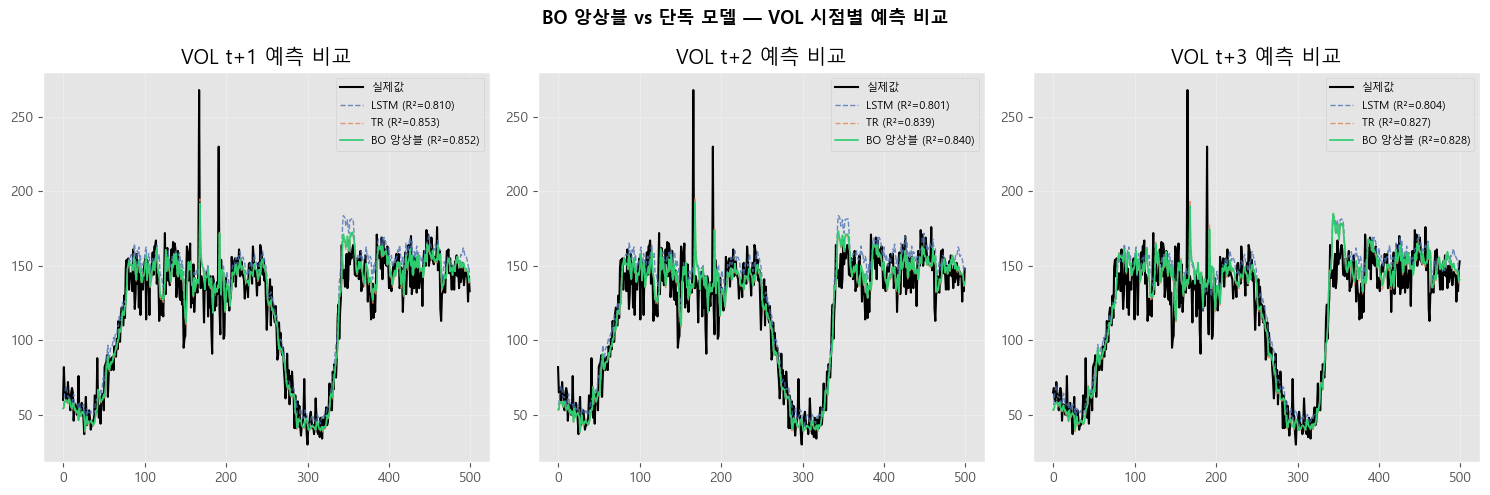

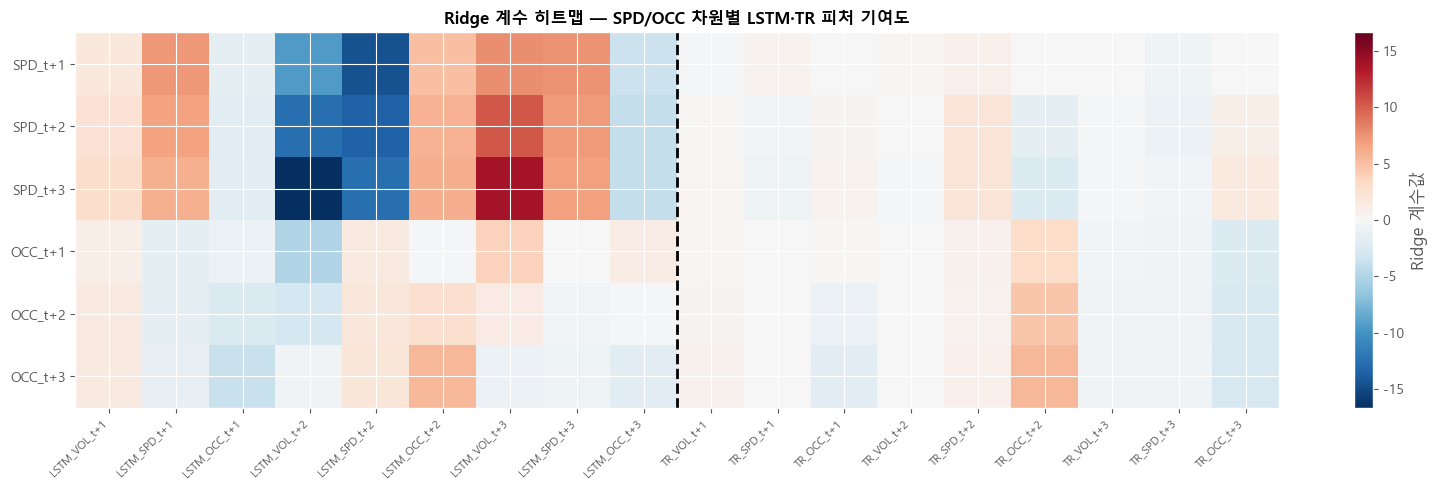

BO / Ridge 추가 그래프 5종 저장 완료


In [17]:
# ══════════════════════════════════════════════════════════════
# BO 전용 추가 그래프 (5종)
# ══════════════════════════════════════════════════════════════
import optuna.visualization.matplotlib as ovm

plt.rcParams.update({
    'font.family'       : 'Malgun Gothic',
    'axes.unicode_minus': False,
})
_ts_g = datetime.now().strftime('%Y%m%d_%H%M%S')
ENS_DIR_G = 'ensemble_results'
os.makedirs(ENS_DIR_G, exist_ok=True)

# ── BO 그래프 1: Optimization History ─────────────────────────
fig = plt.figure(figsize=(10, 5))
ovm.plot_optimization_history(bo_weight_study)
plt.gca().set_title('')
fig.suptitle('BO VOL 가중치 — Optimization History', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(ENS_DIR_G, f'bo_history_{_ts_g}.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── BO 그래프 2: Trial별 Val MSE ──────────────────────────────
trial_vals = [t.value for t in bo_weight_study.trials if t.value is not None]
best_so_far = [min(trial_vals[:i+1]) for i in range(len(trial_vals))]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(len(trial_vals)), trial_vals, 'o-', markersize=3, alpha=0.7, color='steelblue')
axes[0].axhline(bo_weight_study.best_value, color='red', linestyle='--',
                label=f'Best: {bo_weight_study.best_value:.6f}')
axes[0].set_xlabel('Trial'); axes[0].set_ylabel('Val MSE (VOL)')
axes[0].set_title('Trial별 Val MSE'); axes[0].legend(); axes[0].grid(True)

axes[1].plot(range(len(best_so_far)), best_so_far, '-', color='crimson', linewidth=2)
axes[1].set_xlabel('Trial'); axes[1].set_ylabel('Best Val MSE')
axes[1].set_title('누적 최솟값 수렴 곡선'); axes[1].grid(True)

fig.suptitle('BO VOL 가중치 탐색 — Trial 분석', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(ENS_DIR_G, f'bo_trial_analysis_{_ts_g}.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── BO 그래프 3: 최적 가중치 시각화 ──────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
steps = [f't+{s+1}' for s in range(PRED_STEPS)]
lstm_w = best_vol_weights
tr_w   = 1 - best_vol_weights
x = np.arange(PRED_STEPS)
bars1 = ax.bar(x - 0.2, lstm_w, 0.4, label='LSTM 가중치', color='#4C72B0', alpha=0.85)
bars2 = ax.bar(x + 0.2, tr_w,   0.4, label='Transformer 가중치', color='#DD8452', alpha=0.85)
for bar in bars1:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10)
for bar in bars2:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(steps)
ax.set_ylim(0, 1.15); ax.set_ylabel('가중치')
ax.set_title('BO 최적 가중치 — VOL 예측 시점별 LSTM vs Transformer 기여도',
             fontsize=12, fontweight='bold')
ax.axhline(0.5, color='gray', linestyle=':', alpha=0.5, label='동등 가중치 (0.5)')
ax.legend(); ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(ENS_DIR_G, f'bo_weights_bar_{_ts_g}.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── BO 그래프 4: VOL 예측 시점별 성능 비교 (LSTM/TR/BO) ───────
fig, axes = plt.subplots(1, PRED_STEPS, figsize=(15, 5))
for k, col in enumerate(VOL_COLS):
    p_lstm = inverse_vol(lstm_preds_test[:500, col])
    p_tr   = inverse_vol(tr_preds_test2[:500, col])
    p_bo   = inverse_vol(bo_preds_test[:500, col])
    t_true = inverse_vol(y_test_true[:500, col])

    r2_lstm = r2_score(t_true, p_lstm)
    r2_tr   = r2_score(t_true, p_tr)
    r2_bo   = r2_score(t_true, p_bo)

    axes[k].plot(t_true,  color='black',    lw=1.5, label='실제값')
    axes[k].plot(p_lstm,  color='#4C72B0',  lw=1.0, linestyle='--', label=f'LSTM (R²={r2_lstm:.3f})', alpha=0.8)
    axes[k].plot(p_tr,    color='#DD8452',  lw=1.0, linestyle='--', label=f'TR (R²={r2_tr:.3f})', alpha=0.8)
    axes[k].plot(p_bo,    color='#2ecc71',  lw=1.2, linestyle='-',  label=f'BO 앙상블 (R²={r2_bo:.3f})')
    axes[k].set_title(f'VOL t+{k+1} 예측 비교')
    axes[k].legend(fontsize=8); axes[k].grid(True, alpha=0.3)

fig.suptitle('BO 앙상블 vs 단독 모델 — VOL 시점별 예측 비교',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(ENS_DIR_G, f'bo_vol_timeseries_{_ts_g}.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── BO 그래프 5: Ridge 계수 히트맵 (SPD/OCC 기여도) ───────────
coef_matrix = np.array([est.coef_ for est in ridge_model.estimators_])  # (9, 18)
spd_occ_idx = SPD_COLS + OCC_COLS  # 6개 차원만 표시
coef_sub    = coef_matrix[spd_occ_idx]  # (6, 18)

row_labels = ([f'SPD_t+{k+1}' for k in range(PRED_STEPS)] +
               [f'OCC_t+{k+1}' for k in range(PRED_STEPS)])
col_labels_18 = ([f'LSTM_t+{k+1}' for k in range(PRED_STEPS)] * 3 +
                  [f'TR_t+{k+1}' for k in range(PRED_STEPS)] * 3)
col_labels_18 = ([f'LSTM_{t}_t+{k+1}' for k in range(PRED_STEPS) for t in ['VOL','SPD','OCC']] +
                  [f'TR_{t}_t+{k+1}'   for k in range(PRED_STEPS) for t in ['VOL','SPD','OCC']])

fig, ax = plt.subplots(figsize=(16, 5))
import matplotlib.colors as mcolors
vmax = np.abs(coef_sub).max()
im = ax.imshow(coef_sub, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
ax.set_yticks(range(len(row_labels))); ax.set_yticklabels(row_labels)
ax.set_xticks(range(18)); ax.set_xticklabels(col_labels_18, rotation=45, ha='right', fontsize=8)
ax.axvline(8.5, color='black', lw=2, linestyle='--', label='LSTM | TR 구분선')
plt.colorbar(im, ax=ax, label='Ridge 계수값')
ax.set_title('Ridge 계수 히트맵 — SPD/OCC 차원별 LSTM·TR 피처 기여도',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(ENS_DIR_G, f'ridge_coef_heatmap_{_ts_g}.png'), dpi=150, bbox_inches='tight')
plt.show()

print('BO / Ridge 추가 그래프 5종 저장 완료')


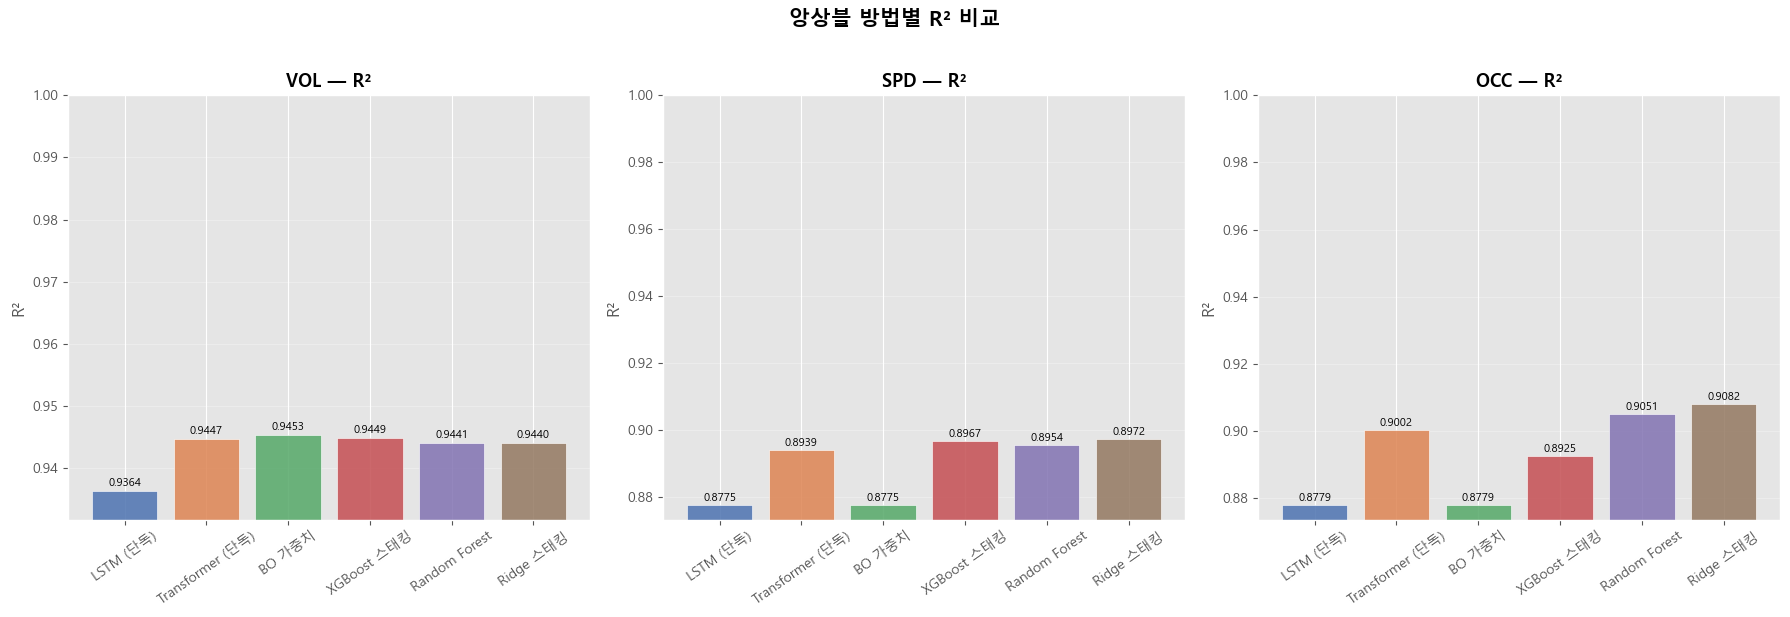

R² 비교 그래프 저장 완료


In [18]:
# ── 그래프 1: 방법별 R² 비교 (타겟별 묶음 막대 그래프) ───────
METHODS  = list(all_results.keys())
COLORS   = ['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax_idx, tname in enumerate(TARGET_NAMES):
    r2_vals  = [all_results[m][tname]['r2']   for m in METHODS]
    rmse_vals= [all_results[m][tname]['rmse'] for m in METHODS]

    bars = axes[ax_idx].bar(METHODS, r2_vals, color=COLORS, alpha=0.85, edgecolor='white')
    axes[ax_idx].set_title(f'{tname} — R²', fontsize=13, fontweight='bold')
    axes[ax_idx].set_ylim(min(r2_vals) * 0.995, 1.0)
    axes[ax_idx].set_ylabel('R²')
    axes[ax_idx].tick_params(axis='x', rotation=35)
    axes[ax_idx].grid(axis='y', alpha=0.3)

    # 값 표시
    for bar, val in zip(bars, r2_vals):
        axes[ax_idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0003,
                          f'{val:.4f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('앙상블 방법별 R² 비교', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(ENS_DIR, f'ens_r2_compare_{_ts}.png'), dpi=150, bbox_inches='tight')
plt.show()
print('R² 비교 그래프 저장 완료')

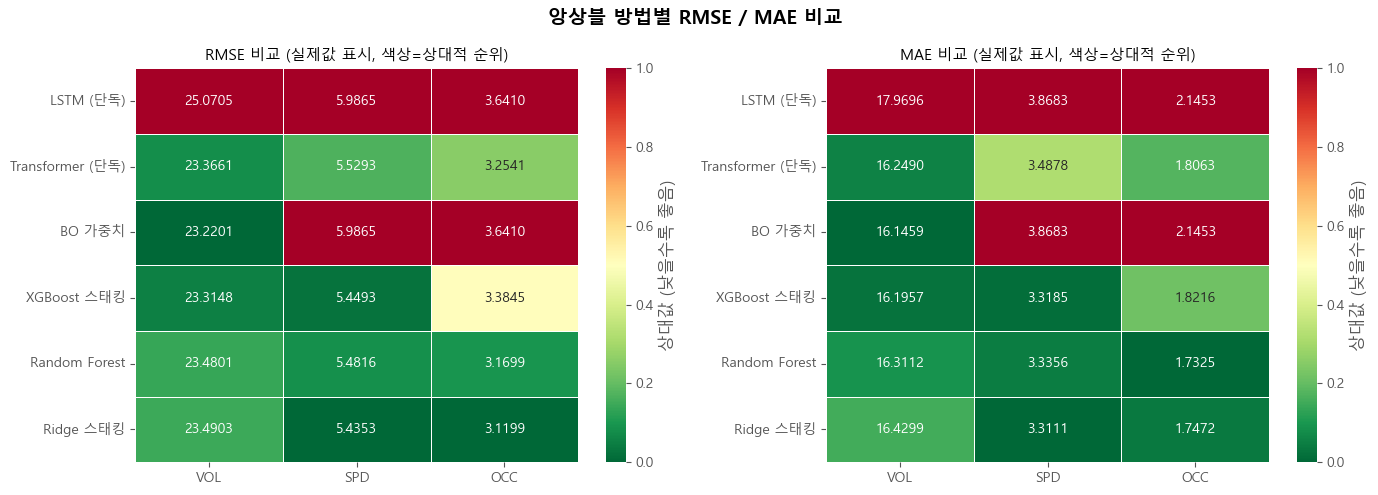

히트맵 저장 완료


In [19]:
# ── 그래프 2: RMSE / MAE 히트맵 ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, ['RMSE', 'MAE']):
    data = pd.DataFrame(
        {tname: [all_results[m][tname][metric.lower()] for m in METHODS] for tname in TARGET_NAMES},
        index=METHODS
    )
    # 각 열을 min-max 정규화하여 상대 비교
    data_norm = (data - data.min()) / (data.max() - data.min() + 1e-10)
    sns.heatmap(data_norm, ax=ax, annot=data.round(4), fmt='.4f',
                cmap='RdYlGn_r', linewidths=0.5, cbar_kws={'label': '상대값 (낮을수록 좋음)'})
    ax.set_title(f'{metric} 비교 (실제값 표시, 색상=상대적 순위)', fontsize=11)
    ax.set_ylabel('')

plt.suptitle('앙상블 방법별 RMSE / MAE 비교', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(ENS_DIR, f'ens_heatmap_{_ts}.png'), dpi=150, bbox_inches='tight')
plt.show()
print('히트맵 저장 완료')

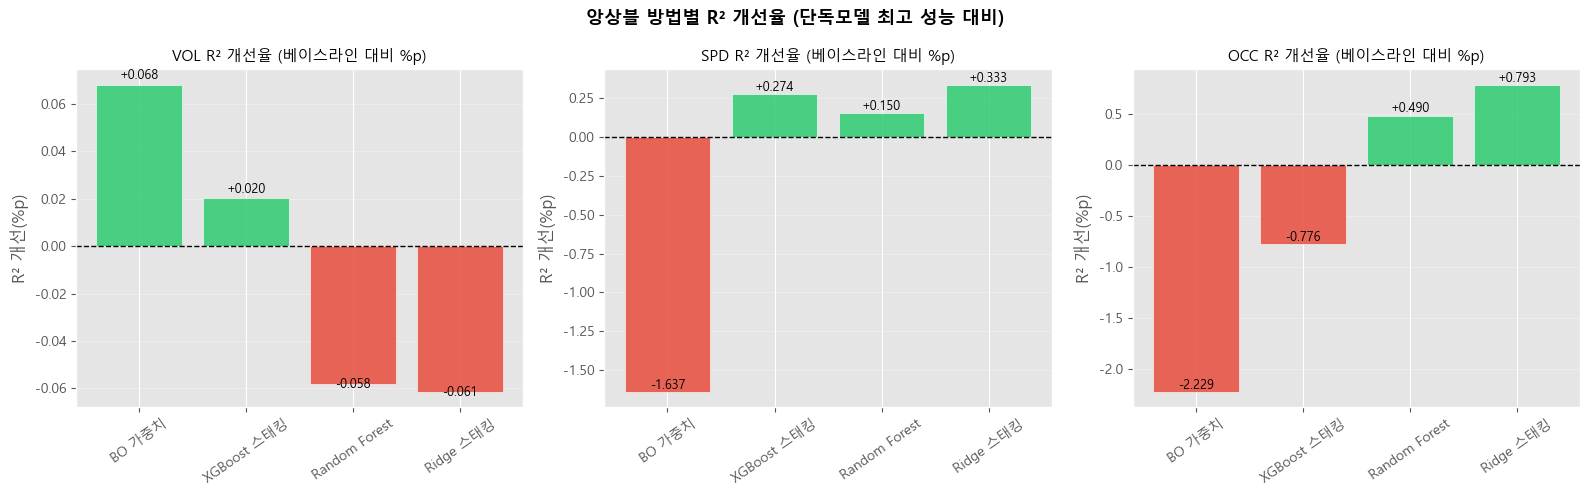

개선율 그래프 저장 완료


In [20]:
# ── 그래프 3: 단독모델 vs 앙상블 개선율 ─────────────────────
# 베이스라인: LSTM과 Transformer 중 더 좋은 것
baseline_r2 = {t: max(lstm_metrics[t]['r2'], tr_metrics[t]['r2']) for t in TARGET_NAMES}

ens_methods = ['BO 가중치', 'XGBoost 스태킹', 'Random Forest', 'Ridge 스태킹']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax_idx, tname in enumerate(TARGET_NAMES):
    improvements = [
        (all_results[m][tname]['r2'] - baseline_r2[tname]) * 100
        for m in ens_methods
    ]
    bar_colors = ['#2ecc71' if v >= 0 else '#e74c3c' for v in improvements]
    bars = axes[ax_idx].bar(ens_methods, improvements, color=bar_colors, alpha=0.85, edgecolor='white')
    axes[ax_idx].axhline(0, color='black', linewidth=1.0, linestyle='--')
    axes[ax_idx].set_title(f'{tname} R² 개선율 (베이스라인 대비 %p)', fontsize=11)
    axes[ax_idx].set_ylabel('R² 개선(%p)')
    axes[ax_idx].tick_params(axis='x', rotation=35)
    axes[ax_idx].grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, improvements):
        axes[ax_idx].text(bar.get_x() + bar.get_width()/2,
                          bar.get_height() + (0.001 if val >= 0 else -0.003),
                          f'{val:+.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('앙상블 방법별 R² 개선율 (단독모델 최고 성능 대비)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(ENS_DIR, f'ens_improvement_{_ts}.png'), dpi=150, bbox_inches='tight')
plt.show()
print('개선율 그래프 저장 완료')

평균 R² 기준 최고 방법: Ridge 스태킹 (R²=0.9165)


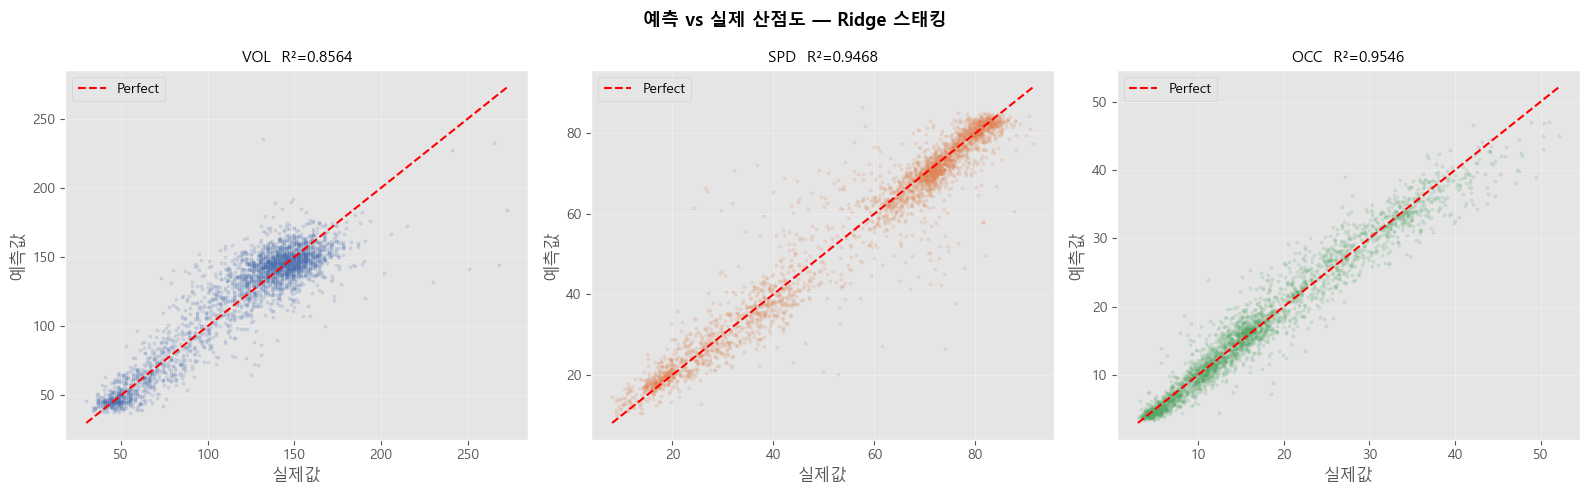

산점도 저장 완료


In [21]:
# ── 그래프 4: 예측값 vs 실제값 산점도 (최고 앙상블 방법) ─────
# R² 기준 최고 방법 자동 선택
avg_r2 = {m: np.mean([all_results[m][t]['r2'] for t in TARGET_NAMES]) for m in all_results}
best_method = max(avg_r2, key=avg_r2.get)
best_preds = {
    'LSTM (단독)'        : lstm_preds_test,
    'Transformer (단독)' : tr_preds_test2,
    'BO 가중치'          : bo_preds_test,
    'XGBoost 스태킹'     : xgb_preds_test,
    'Random Forest'      : rf_preds_test,
    'Ridge 스태킹'       : ridge_preds_test,
}
print(f'평균 R² 기준 최고 방법: {best_method} (R²={avg_r2[best_method]:.4f})')

PLOT_N = 3000
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
bp = best_preds[best_method]

for ax_idx, (tname, inv_fn) in enumerate(zip(TARGET_NAMES, inv_funcs)):
    p = inv_fn(bp[:PLOT_N, ax_idx])
    t = inv_fn(y_test_true[:PLOT_N, ax_idx])
    axes[ax_idx].scatter(t, p, alpha=0.15, s=5, color=COLORS[ax_idx])
    lim_min = min(t.min(), p.min())
    lim_max = max(t.max(), p.max())
    axes[ax_idx].plot([lim_min, lim_max], [lim_min, lim_max], 'r--', linewidth=1.5, label='Perfect')
    r2 = r2_score(t, p)
    axes[ax_idx].set_title(f'{tname}  R²={r2:.4f}', fontsize=11)
    axes[ax_idx].set_xlabel('실제값'); axes[ax_idx].set_ylabel('예측값')
    axes[ax_idx].legend(); axes[ax_idx].grid(True, alpha=0.3)

plt.suptitle(f'예측 vs 실제 산점도 — {best_method}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(ENS_DIR, f'ens_scatter_{_ts}.png'), dpi=150, bbox_inches='tight')
plt.show()
print('산점도 저장 완료')

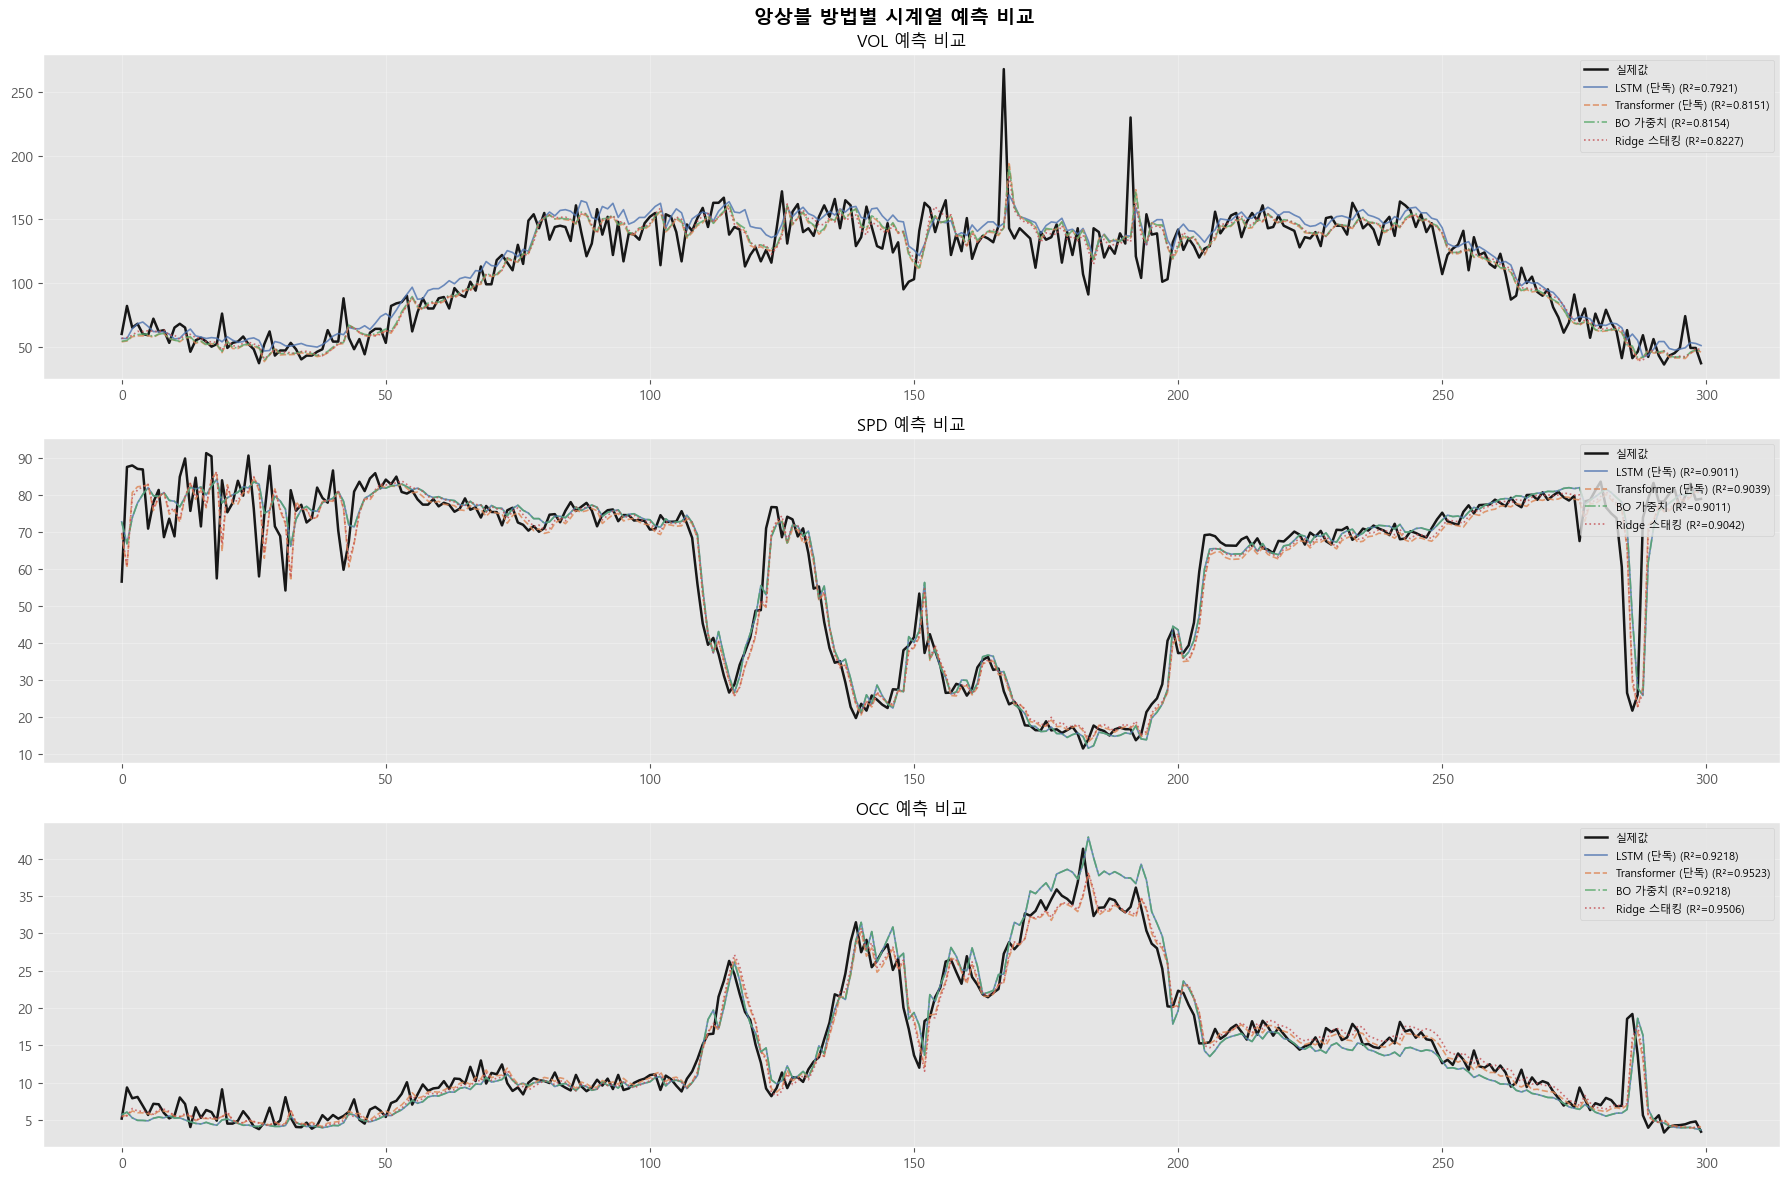

시계열 비교 그래프 저장 완료


In [22]:
# ── 그래프 5: 시계열 예측 비교 (모든 방법 오버레이) ──────────
PLOT_N2 = 300

fig, axes = plt.subplots(3, 1, figsize=(18, 12))
plot_methods = ['LSTM (단독)', 'Transformer (단독)', 'BO 가중치', 'Ridge 스태킹']
line_styles  = ['-', '--', '-.', ':']
line_colors  = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

for ax_idx, (tname, inv_fn) in enumerate(zip(TARGET_NAMES, inv_funcs)):
    # 실제값
    true_vals = inv_fn(y_test_true[:PLOT_N2, ax_idx])
    axes[ax_idx].plot(true_vals, color='black', linewidth=1.8, label='실제값', alpha=0.9)

    for method, ls, lc in zip(plot_methods, line_styles, line_colors):
        pred_vals = inv_fn(best_preds[method][:PLOT_N2, ax_idx])
        r2 = r2_score(true_vals, pred_vals)
        axes[ax_idx].plot(pred_vals, linestyle=ls, color=lc, linewidth=1.2,
                          label=f'{method} (R²={r2:.4f})', alpha=0.8)

    axes[ax_idx].set_title(f'{tname} 예측 비교', fontsize=12)
    axes[ax_idx].legend(loc='upper right', fontsize=8)
    axes[ax_idx].grid(True, alpha=0.3)

plt.suptitle('앙상블 방법별 시계열 예측 비교', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(ENS_DIR, f'ens_timeseries_{_ts}.png'), dpi=150, bbox_inches='tight')
plt.show()
print('시계열 비교 그래프 저장 완료')

## 11. 최종 결과 저장 (보고서용)

In [23]:
import json as _json
from datetime import datetime

_ts = datetime.now().strftime('%Y%m%d_%H%M%S')

# ── 1. 다익스트라용 핵심 파일 저장 ────────────────────────────
# VOL BO 가중치 (9차원: VOL위치만 실제값, 나머지 0.5)
np.save('bo_best_weights.npy', best_weights_9d)
print(f'[저장] bo_best_weights.npy  shape={best_weights_9d.shape}')
print(f'       VOL 가중치: {best_weights_9d[VOL_COLS]}')

# Ridge 메타 학습기 (SPD/OCC 앙상블)
with open('ridge_model.pkl', 'wb') as f:
    pickle.dump(ridge_model, f)
print('[저장] ridge_model.pkl')

# ── 2. 기존 앙상블 결과 JSON ───────────────────────────────────
ENS_DIR = 'ensemble_results'
os.makedirs(ENS_DIR, exist_ok=True)

final_report = {
    'timestamp'     : _ts,
    'vol_ensemble'  : 'BO 가중치',
    'spd_occ_ensemble': 'Ridge 스태킹',
    'bo_vol_weights': {f'VOL_t+{k+1}': round(float(best_vol_weights[k]), 4)
                       for k in range(PRED_STEPS)},
    'ridge_best_alpha': round(float(best_alpha), 4),
    'detailed_results': {
        method: {
            target: {k: round(v, 4) for k, v in metrics.items()}
            for target, metrics in method_metrics.items()
        }
        for method, method_metrics in all_results.items()
    },
}

report_path = os.path.join(ENS_DIR, f'ensemble_final_report_{_ts}.json')
with open(report_path, 'w', encoding='utf-8') as f:
    _json.dump(final_report, f, ensure_ascii=False, indent=2)

# ── 3. 결과 CSV ────────────────────────────────────────────────
rows = []
for method, metrics in all_results.items():
    for tname, m in metrics.items():
        rows.append({'방법': method, '타겟': tname,
                     'RMSE': round(m['rmse'], 4),
                     'MAE' : round(m['mae'],  4),
                     'R²'  : round(m['r2'],   4)})
df_results = pd.DataFrame(rows)
df_results.to_csv(os.path.join(ENS_DIR, f'ensemble_comparison_{_ts}.csv'),
                  index=False, encoding='utf-8-sig')

# ── 4. 요약 출력 ───────────────────────────────────────────────
print('\n' + '='*65)
print('  앙상블 최종 결과 요약')
print('  (VOL=BO앙상블, SPD/OCC=Ridge앙상블 기준)')
print('='*65)
print(f"{'방법':<22} {'VOL-R²':>8} {'SPD-R²':>8} {'OCC-R²':>8} {'평균R²':>8}")
print('-'*65)
avg_r2 = {m: np.mean([all_results[m][t]['r2'] for t in TARGET_NAMES])
          for m in all_results}
for method, r2_avg in sorted(avg_r2.items(), key=lambda x: x[1], reverse=True):
    v = all_results[method]
    marker = ' ✅' if method in ('BO 가중치', 'Ridge 스태킹') else ''
    print(f"{method:<22} {v['VOL']['r2']:>8.4f} {v['SPD']['r2']:>8.4f}"
          f" {v['OCC']['r2']:>8.4f} {r2_avg:>8.4f}{marker}")
print('='*65)
print()
print('저장 완료:')
print('  bo_best_weights.npy   ← 다익스트라 VOL 앙상블 가중치')
print('  ridge_model.pkl       ← 다익스트라 SPD/OCC 앙상블 모델')
print(f'  {report_path}')


[저장] bo_best_weights.npy  shape=(9,)
       VOL 가중치: [0.12533859 0.08759957 0.14027514]
[저장] ridge_model.pkl

  앙상블 최종 결과 요약
  (VOL=BO앙상블, SPD/OCC=Ridge앙상블 기준)
방법                       VOL-R²   SPD-R²   OCC-R²     평균R²
-----------------------------------------------------------------
Ridge 스태킹                0.9440   0.8972   0.9082   0.9165 ✅
Random Forest            0.9441   0.8954   0.9051   0.9149
Transformer (단독)         0.9447   0.8939   0.9002   0.9129
XGBoost 스태킹              0.9449   0.8967   0.8925   0.9113
BO 가중치                   0.9453   0.8775   0.8779   0.9003 ✅
LSTM (단독)                0.9364   0.8775   0.8779   0.8973

저장 완료:
  bo_best_weights.npy   ← 다익스트라 VOL 앙상블 가중치
  ridge_model.pkl       ← 다익스트라 SPD/OCC 앙상블 모델
  ensemble_results\ensemble_final_report_20260509_014917.json


In [16]:
# 시간 아끼려고 임시로 코드 작성 BO와 Ridge만 저장 


import os
import pickle
import numpy as np
from datetime import datetime

# ── BO 가중치 저장 ─────────────────────────────────────────────
# BO 앙상블 셀 실행 후 best_vol_weights, best_weights_9d 변수가 있어야 함
np.save('bo_best_weights.npy', best_weights_9d)
print(f'[저장] bo_best_weights.npy  shape={best_weights_9d.shape}')
print(f'       VOL 가중치: {best_weights_9d[VOL_COLS]}')

# ── Ridge 모델 저장 ────────────────────────────────────────────
# Ridge 스태킹 셀 실행 후 ridge_model 변수가 있어야 함
with open('ridge_model.pkl', 'wb') as f:
    pickle.dump(ridge_model, f)
print('[저장] ridge_model.pkl')

print('\n저장 완료!')
print('  bo_best_weights.npy  ← 다익스트라 VOL 앙상블 가중치')
print('  ridge_model.pkl      ← 다익스트라 SPD/OCC 앙상블 모델')

[저장] bo_best_weights.npy  shape=(9,)
       VOL 가중치: [0.12533859 0.08759957 0.14027514]
[저장] ridge_model.pkl

저장 완료!
  bo_best_weights.npy  ← 다익스트라 VOL 앙상블 가중치
  ridge_model.pkl      ← 다익스트라 SPD/OCC 앙상블 모델
